<a href="https://colab.research.google.com/github/wbwu2021-oss/aboration_and_crime_rate/blob/EDA/abortions_and_crime_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [86]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

from google.colab import drive
drive.mount('/content/drive')

ABORTION_PATH = "/content/drive/MyDrive/stat520/NationalAndStatePregnancy_PublicUse.csv"
ABORTION_PATH2 = "/content/drive/MyDrive/stat520/number_of_legal_abortions_reported_in_the_u.s._from_1973_to_2022_in_1000s (1).csv"
CRIME_PATH = "/content/drive/MyDrive/stat520/state_crime.csv"
LAG_YEARS = [0, 10, 18, 20]
CRIME_START, CRIME_END = 1960, 2020

STATE_TO_POSTAL = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
    "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI",
    "South Carolina": "SC", "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX",
    "Utah": "UT", "United States": "US", "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
}

PROP = "Data.Rates.Property.All"
VIOL = "Data.Rates.Violent.All"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
abortions = load_abortions(ABORTION_PATH)
crimes = load_crimes(CRIME_PATH)


ab_lag = lagged_abortions(abortions, LAG_YEARS)
merged = merge_with_crimes(ab_lag, crimes, LAG_YEARS)

Unmatched state names (should be none): 0
state
AK    35
AL    35
AR    35
AZ    35
CA    35
CO    35
CT    35
DC    35
DE    35
FL    35
GA    35
HI    35
IA    35
ID    35
IL    35
IN    35
KS    35
KY    35
LA    35
MA    35
MD    35
ME    35
MI    35
MN    35
MO    35
MS    35
MT    35
NC    35
ND    35
NE    35
NH    35
NJ    35
NM    35
NV    35
NY    35
OH    35
OK    35
OR    35
PA    35
RI    35
SC    35
SD    35
TN    35
TX    35
US    35
UT    35
VA    35
VT    35
WA    35
WI    35
WV    35
WY    35
Name: count, dtype: int64 



In [32]:
merged_ac = crimes.copy()

for lag in LAG_YEARS:
    ab = abortions[abortions["year"].between(1985 - lag, 2020 - lag)].copy()
    ab["cohort_year"] = ab["year"]
    ab["abortionratetotal_100k"] = np.where(
        ab["population1544"] > 0,
        ab["abortionstotal"] / ab["population1544"] * 100_000,
        np.nan,
    )
    ab["year"] = ab["year"] + lag

    ab = ab[["state", "year", "cohort_year", "abortionratetotal_100k",
             "abortionstotal", "population1544"]]
    ab = ab.rename(columns={
        "cohort_year": f"cohort_year_lag{lag}",
        "abortionratetotal_100k": f"abortionratetotal_100k_lag{lag}",
        "abortionstotal": f"abortionstotal_lag{lag}",
        "population1544": f"population1544_lag{lag}",
    })

    merged_ac = merged_ac.merge(ab, on=["state", "year"], how="left")

merged_ac = merged_ac.sort_values(["state", "year"]).reset_index(drop=True)

In [33]:
merged_ac

,Data.Population,Data.Rates.Property.All,Data.Rates.Property.Burglary,Data.Rates.Property.Larceny,Data.Rates.Property.Motor,Data.Rates.Violent.All,Data.Rates.Violent.Assault,Data.Rates.Violent.Murder,Data.Rates.Violent.Rape,Data.Rates.Violent.Robbery,Data.Totals.Property.All,Data.Totals.Property.Burglary,Data.Totals.Property.Larceny,Data.Totals.Property.Motor,Data.Totals.Violent.All,Data.Totals.Violent.Assault,Data.Totals.Violent.Murder,Data.Totals.Violent.Rape,Data.Totals.Violent.Robbery,total_crime,total_crime_rate,year,state,cohort_year_lag0,abortionratetotal_100k_lag0,abortionstotal_lag0,population1544_lag0,cohort_year_lag10,abortionratetotal_100k_lag10,abortionstotal_lag10,population1544_lag10,cohort_year_lag18,abortionratetotal_100k_lag18,abortionstotal_lag18,population1544_lag18,cohort_year_lag20,abortionratetotal_100k_lag20,abortionstotal_lag20,population1544_lag20
0,521000,5295.2,1191.7,3497.1,606.3,581.8,401.9,9.8,77.2,92.9,27588,6209,18220,3159,3031,2094,51,402,484,30619,5877.0,1985,AK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,534000,5675.5,1161.8,3909.9,603.7,570.4,401.1,8.6,72.7,88.0,30307,6204,20879,3224,3046,2142,46,388,470,33353,6245.9,1986,AK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,525000,4922.1,970.1,3465.7,486.3,455.4,307.2,10.1,65.0,73.1,25841,5093,18195,2553,2391,1613,53,341,384,28232,5377.5,1987,AK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,513000,4398.8,842.3,3101.6,455.0,522.8,386.5,5.7,57.7,72.9,22566,4321,15911,2334,2682,1983,29,296,374,25248,4921.6,1988,AK,1988.0,1976.038701,2700.0,136637.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,527000,4282.2,826.9,3000.2,455.0,497.7,369.3,8.0,52.9,67.6,22567,4358,15811,2398,2623,1946,42,279,356,25190,4779.9,1989,AK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1815,586107,1902.6,300.6,1500.9,101.0,222.1,179.8,2.7,29.5,10.1,11151,1762,8797,592,1302,1054,16,173,59,12453,2124.7,2015,WY,2015.0,733.928329,810.0,110365.0,2005.0,1202.859256,1220.0,101425.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1816,585501,1957.3,302.5,1518.2,136.6,244.2,195.7,3.4,35.0,10.1,11460,1771,8889,800,1430,1146,20,205,59,12890,2201.5,2016,WY,2016.0,701.984702,770.0,109689.0,2006.0,1178.214808,1200.0,101849.0,NaN,NaN,NaN,NaN,1996.0,1501.598327,1630.0,108551.0
1817,579315,1830.4,275.0,1421.0,134.5,237.5,176.4,2.6,45.4,13.1,10604,1593,8232,779,1376,1022,15,263,76,11980,2067.9,2017,WY,2017.0,665.434381,720.0,108200.0,2007.0,1133.764875,1170.0,103196.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1818,577737,1785.1,264.0,1375.9,145.2,212.2,150.6,2.3,42.1,17.3,10313,1525,7949,839,1226,870,13,243,100,11539,1997.3,2018,WY,2018.0,657.717996,710.0,107949.0,2008.0,1015.024274,1060.0,104431.0,2000.0,1999.655562,2090.0,104518.0,NaN,NaN,NaN,NaN


In [58]:
CRIME_START = 1960
crimes = load_crimes(CRIME_PATH)
crimes["year"].agg(["min", "max"])

Unmatched state names (should be none): 0
state
AK    60
AL    60
AR    60
AZ    60
CA    60
CO    60
CT    60
DC    60
DE    60
FL    60
GA    60
HI    60
IA    60
ID    60
IL    60
IN    60
KS    60
KY    60
LA    60
MA    60
MD    60
ME    60
MI    60
MN    60
MO    60
MS    60
MT    60
NC    60
ND    60
NE    60
NH    60
NJ    60
NM    60
NV    60
NY    55
OH    60
OK    60
OR    60
PA    60
RI    60
SC    60
SD    60
TN    60
TX    60
US    60
UT    60
VA    60
VT    60
WA    60
WI    60
WV    60
WY    60
Name: count, dtype: int64 



,year
min,1960
max,2019


In [59]:
import statsmodels.formula.api as smf

AB_START, AB_END = 1973, 2019
lags = range(0, 31)
rows = []

ab_all = abortions[abortions["year"].between(AB_START, AB_END)].copy()
ab_all["abortionratetotal_100k"] = np.where(
    ab_all["population1544"] > 0,
    ab_all["abortionstotal"] / ab_all["population1544"] * 100_000,
    np.nan,
)
ab_all["cohort_year"] = ab_all["year"]

for lag in lags:
    ab = ab_all[["state", "cohort_year", "abortionratetotal_100k"]].copy()
    ab["year"] = ab["cohort_year"] + lag          # crime year = cohort year + lag

    d = crimes.merge(ab, on=["state", "year"], how="inner")
    d = d[d["state"] != "US"].dropna(subset=["abortionratetotal_100k", "total_crime_rate"]).copy()

    if d["state"].nunique() < 10 or d["year"].nunique() < 3:
        print(f"lag {lag}: {len(d)} obs, {d['state'].nunique()} states, skipped")
        continue

    d["year_f"] = d["year"].astype(str)
    fit = smf.ols(
        "total_crime_rate ~ abortionratetotal_100k + C(state) + C(year_f)", data=d
    ).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["state"])[0]})

    ci = fit.conf_int().loc["abortionratetotal_100k"]
    rows.append({
        "lag": lag,
        "n_obs": int(fit.nobs),
        "n_states": d["state"].nunique(),
        "cohorts": f"{d['cohort_year'].min()}-{d['cohort_year'].max()}",
        "crime_years": f"{d['year'].min()}-{d['year'].max()}",
        "coef": fit.params["abortionratetotal_100k"],
        "se": fit.bse["abortionratetotal_100k"],
        "ci_low": ci[0],
        "ci_high": ci[1],
        "p_value": fit.pvalues["abortionratetotal_100k"],
    })

results = pd.DataFrame(rows)
results.round(4)

lag 24: 102 obs, 51 states, skipped
lag 25: 102 obs, 51 states, skipped
lag 26: 102 obs, 51 states, skipped
lag 27: 102 obs, 51 states, skipped
lag 28: 51 obs, 51 states, skipped
lag 29: 51 obs, 51 states, skipped
lag 30: 51 obs, 51 states, skipped


,lag,n_obs,n_states,cohorts,crime_years,coef,se,ci_low,ci_high,p_value
0,0,969,51,1988-2019,1988-2019,0.5843,0.0995,0.3893,0.7794,0.0000
1,1,918,51,1988-2018,1989-2019,0.6232,0.0884,0.4501,0.7964,0.0000
2,2,867,51,1988-2017,1990-2019,0.5926,0.0791,0.4375,0.7476,0.0000
3,3,816,51,1988-2016,1991-2019,0.6316,0.0738,0.4869,0.7762,0.0000
4,4,765,51,1988-2015,1992-2019,0.6327,0.0877,0.4609,0.8046,0.0000
5,5,714,51,1988-2014,1993-2019,0.5821,0.0797,0.4258,0.7384,0.0000
6,6,663,51,1988-2013,1994-2019,0.4982,0.0727,0.3557,0.6408,0.0000
7,7,612,51,1988-2012,1995-2019,0.5482,0.0953,0.3615,0.7350,0.0000
8,8,561,51,1988-2011,1996-2019,0.5009,0.1051,0.2950,0.7068,0.0000
9,9,510,51,1988-2010,1997-2019,0.3832,0.0882,0.2103,0.5560,0.0000


In [158]:
lags = range(18, 27)

wide = abortions[abortions["year"].between(1973, 2019)].copy()
wide = wide.rename(columns={"year": "cohort_year"})

pop = wide["population1544"]
wide["abortionrate_100k"]  = np.where(pop > 0, wide["abortionstotal"]    / pop * 100_000, np.nan)
wide["birthrate_100k"]     = np.where(pop > 0, wide["birthstotal"]       / pop * 100_000, np.nan)
wide["pregnancyrate_100k"] = np.where(pop > 0, wide["pregnanciestotal"]  / pop * 100_000, np.nan)

crime_map = {
    "total_crime_rate": "total_crime",
    "Data.Rates.Property.All": "property_crime",
    "Data.Rates.Violent.All": "violent_crime",
}

for lag in lags:
    c = crimes[["state", "year", *crime_map.keys()]].copy()
    c["cohort_year"] = c["year"] - lag
    c = c.drop(columns="year")
    c = c.rename(columns={old: f"{new}_plus{lag}" for old, new in crime_map.items()})
    wide = wide.merge(c, on=["state", "cohort_year"], how="left")


tc_cols = [f"total_crime_plus{lag}" for lag in lags]
wide["total_crime_mean_18_26"] = wide[tc_cols].mean(axis=1)
wide["n_crime_years_18_26"]    = wide[tc_cols].notna().sum(axis=1)

wide = wide.sort_values(["state", "cohort_year"]).reset_index(drop=True)
wide.head()


# how many cohorts have crime data at each lag (states only)
st = wide[wide["state"] != "US"]
print(st[tc_cols].notna().sum())

# correlation of abortion rate with crime at each future lag
for lag in lags:
    d = st[["abortionrate_100k", f"total_crime_plus{lag}"]].dropna()
    print(lag, len(d), round(d["abortionrate_100k"].corr(d[f"total_crime_plus{lag}"]), 4))

total_crime_plus18    204
total_crime_plus19    204
total_crime_plus20    153
total_crime_plus21    153
total_crime_plus22    153
total_crime_plus23    153
total_crime_plus24    102
total_crime_plus25    102
total_crime_plus26    102
dtype: int64
18 204 0.3602
19 204 0.3479
20 153 0.3639
21 153 0.3439
22 153 0.3693
23 153 0.3596
24 102 0.383
25 102 0.3492
26 102 0.3848


In [66]:
rows = []
for lag in range(18, 27):
    y = f"total_crime_plus{lag}"
    d = wide[wide["state"] != "US"].dropna(subset=["abortionrate_100k", y]).copy()
    d["cohort_f"] = d["cohort_year"].astype(str)

    fit = smf.ols(f"{y} ~ abortionrate_100k + C(state) + C(cohort_f)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["state"])[0]}
    )
    lo, hi = fit.conf_int().loc["abortionrate_100k"]
    rows.append({"lag": lag, "n_obs": int(fit.nobs), "n_states": d["state"].nunique(),
                 "coef": fit.params["abortionrate_100k"], "se": fit.bse["abortionrate_100k"],
                 "ci_low": lo, "ci_high": hi, "p_value": fit.pvalues["abortionrate_100k"]})

rows

[{'lag': 18,
  'n_obs': 204,
  'n_states': 51,
  'coef': np.float64(-0.08746026688521188),
  'se': np.float64(0.07588654740722205),
  'ci_low': -0.2361951667144585,
  'ci_high': 0.061274632944034735,
  'p_value': np.float64(0.24911014427341538)},
 {'lag': 19,
  'n_obs': 204,
  'n_states': 51,
  'coef': np.float64(-0.1057043785301082),
  'se': np.float64(0.06152249268489176),
  'ci_low': -0.22628624843162498,
  'ci_high': 0.014877491371408591,
  'p_value': np.float64(0.08577071792487592)},
 {'lag': 20,
  'n_obs': 153,
  'n_states': 51,
  'coef': np.float64(-0.050371213342998405),
  'se': np.float64(0.05795597669069134),
  'ci_low': -0.1639628403455963,
  'ci_high': 0.06322041365959949,
  'p_value': np.float64(0.3847766397717196)},
 {'lag': 21,
  'n_obs': 153,
  'n_states': 51,
  'coef': np.float64(0.06950981424351407),
  'se': np.float64(0.054335890687771754),
  'ci_low': -0.036986574572423866,
  'ci_high': 0.17600620305945203,
  'p_value': np.float64(0.20080497744177006)},
 {'lag': 22,

In [67]:
lags = range(18, 27)

# national cohort-level rates
us = abortions[(abortions["state"] == "US") & abortions["year"].between(1973, 2019)].copy()
us = us.rename(columns={"year": "cohort_year"})

pop = us["population1544"]
us["abortionrate_100k"]  = np.where(pop > 0, us["abortionstotal"]   / pop * 100_000, np.nan)
us["birthrate_100k"]     = np.where(pop > 0, us["birthstotal"]      / pop * 100_000, np.nan)
us["pregnancyrate_100k"] = np.where(pop > 0, us["pregnanciestotal"] / pop * 100_000, np.nan)

# national crime, one set of columns per lag
crime_map = {
    "total_crime_rate": "total_crime",
    "Data.Rates.Property.All": "property_crime",
    "Data.Rates.Violent.All": "violent_crime",
}
us_crime = crimes[crimes["state"] == "US"]

for lag in lags:
    c = us_crime[["year", *crime_map.keys()]].copy()
    c["cohort_year"] = c["year"] - lag
    c = c.drop(columns="year")
    c = c.rename(columns={old: f"{new}_plus{lag}" for old, new in crime_map.items()})
    us = us.merge(c, on="cohort_year", how="left")

tc_cols = [f"total_crime_plus{lag}" for lag in lags]
us["total_crime_mean_18_26"] = us[tc_cols].mean(axis=1)
us["n_crime_years_18_26"] = us[tc_cols].notna().sum(axis=1)

us = us.sort_values("cohort_year").reset_index(drop=True)
us[["cohort_year", "abortionrate_100k", "birthrate_100k", "pregnancyrate_100k",
    *tc_cols, "total_crime_mean_18_26", "n_crime_years_18_26"]].head(10)

,cohort_year,abortionrate_100k,birthrate_100k,pregnancyrate_100k,total_crime_plus18,total_crime_plus19,total_crime_plus20,total_crime_plus21,total_crime_plus22,total_crime_plus23,total_crime_plus24,total_crime_plus25,total_crime_plus26,total_crime_mean_18_26,n_crime_years_18_26
0,1973,1634.798298,6887.236329,10062.963918,5898.4,5661.4,5487.1,5373.8,5275.0,5087.6,4927.3,4620.1,4266.6,5177.477778,9
1,1974,1929.530034,6785.485679,10265.073153,5661.4,5487.1,5373.8,5275.0,5087.6,4927.3,4620.1,4266.6,4124.8,4980.411111,9
2,1975,2172.399957,6604.770588,10315.354994,5487.1,5373.8,5275.0,5087.6,4927.3,4620.1,4266.6,4124.8,4162.6,4813.877778,9
3,1976,2419.594294,6499.416409,10460.862442,5373.8,5275.0,5087.6,4927.3,4620.1,4266.6,4124.8,4162.6,4125.0,4662.533333,9
4,1977,2641.488714,6673.700071,10914.080880,5275.0,5087.6,4927.3,4620.1,4266.6,4124.8,4162.6,4125.0,4067.0,4517.333333,9
5,1978,2766.476654,6541.883183,10893.394344,5087.6,4927.3,4620.1,4266.6,4124.8,4162.6,4125.0,4067.0,3977.3,4373.144444,9
6,1979,2877.962805,6714.928836,11223.664849,4927.3,4620.1,4266.6,4124.8,4162.6,4125.0,4067.0,3977.3,3900.5,4241.244444,9
7,1980,2927.494248,6805.413844,11386.742923,4620.1,4266.6,4124.8,4162.6,4125.0,4067.0,3977.3,3900.5,3825.9,4118.866667,9
8,1981,2925.012901,6730.044233,11293.568013,4266.6,4124.8,4162.6,4125.0,4067.0,3977.3,3900.5,3825.9,3748.2,4021.988889,9
9,1982,2877.402808,6728.669500,11239.553071,4124.8,4162.6,4125.0,4067.0,3977.3,3900.5,3825.9,3748.2,3673.2,3956.055556,9


In [68]:
from scipy import stats

for lag in lags:
    d = us[["abortionrate_100k", f"total_crime_plus{lag}"]].dropna()
    r, p = stats.pearsonr(d["abortionrate_100k"], d[f"total_crime_plus{lag}"])
    rho, ps = stats.spearmanr(d["abortionrate_100k"], d[f"total_crime_plus{lag}"])
    print(f"lag {lag}: n={len(d)}  pearson r={r:.3f} (p={p:.3f})  spearman rho={rho:.3f} (p={ps:.3f})")



lag 18: n=29  pearson r=0.085 (p=0.660)  spearman rho=0.349 (p=0.064)
lag 19: n=28  pearson r=0.025 (p=0.899)  spearman rho=0.305 (p=0.114)
lag 20: n=27  pearson r=-0.042 (p=0.836)  spearman rho=0.258 (p=0.193)
lag 21: n=26  pearson r=-0.116 (p=0.572)  spearman rho=0.209 (p=0.306)
lag 22: n=25  pearson r=-0.185 (p=0.375)  spearman rho=0.155 (p=0.461)
lag 23: n=24  pearson r=-0.237 (p=0.266)  spearman rho=0.109 (p=0.613)
lag 24: n=23  pearson r=-0.278 (p=0.200)  spearman rho=0.049 (p=0.823)
lag 25: n=22  pearson r=-0.317 (p=0.151)  spearman rho=-0.022 (p=0.923)
lag 26: n=21  pearson r=-0.358 (p=0.111)  spearman rho=-0.104 (p=0.654)


In [69]:
import statsmodels.formula.api as smf

d = us.dropna(subset=["abortionrate_100k", "total_crime_mean_18_26"])
d = d[d["n_crime_years_18_26"] == 9]

fit = smf.ols("total_crime_mean_18_26 ~ abortionrate_100k", data=d).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3}
)
print(f"n={int(fit.nobs)}, cohorts {d['cohort_year'].min()}-{d['cohort_year'].max()}")
print(fit.summary().tables[1])

n=21, cohorts 1973-1993
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          6775.0625    943.973      7.177      0.000    4924.909    8625.216
abortionrate_100k    -1.0921      0.361     -3.024      0.002      -1.800      -0.384


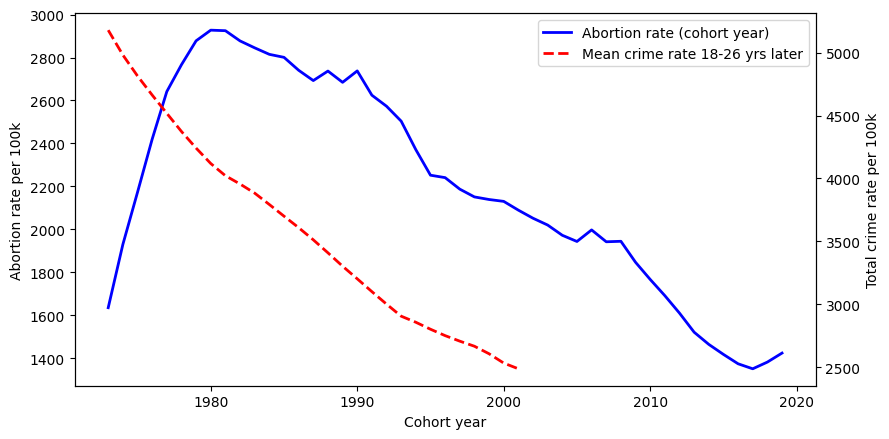

In [70]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(us["cohort_year"], us["abortionrate_100k"], color="blue", lw=2, label="Abortion rate (cohort year)")
ax.set_xlabel("Cohort year")
ax.set_ylabel("Abortion rate per 100k")
ax2 = ax.twinx()
ax2.plot(us["cohort_year"], us["total_crime_mean_18_26"], color="red", lw=2, ls="--",
         label="Mean crime rate 18-26 yrs later")
ax2.set_ylabel("Total crime rate per 100k")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="best")
plt.tight_layout(); plt.show()

In [83]:


from scipy import stats

ab_src = abortions
lags = range(18, 27)

start = ab_src[ab_src["year"].between(1960, 2019)][
    ["state", "year", "abortionstotal", "birthstotal", "population1544"]].copy()
start = start.rename(columns={"year": "start_year"})
pop = start["population1544"]
start["abortionrate_100k"] = np.where(pop > 0, start["abortionstotal"] / pop * 100_000, np.nan)
start["birthrate_100k"]    = np.where(pop > 0, start["birthstotal"]    / pop * 100_000, np.nan)
start = start.drop(columns=["abortionstotal", "birthstotal", "population1544"])

cr = crimes[["state", "year", "total_crime_rate"]]

start = start.merge(
    cr.rename(columns={"year": "start_year", "total_crime_rate": "crime_start"}),
    on=["state", "start_year"], how="left")

for lag in lags:
    start = start.merge(
        cr.assign(start_year=cr["year"] - lag)
          .drop(columns="year")
          .rename(columns={"total_crime_rate": f"crime_plus{lag}"}),
        on=["state", "start_year"], how="left")

crime_cols = [f"crime_plus{l}" for l in lags]
start["crime_mean_18_26"] = start[crime_cols].mean(axis=1)
start = start.sort_values(["state", "start_year"]).reset_index(drop=True)

def lag_corrs(df, x="abortionrate_100k"):
    out = []
    for lag in lags:
        d = df[[x, f"crime_plus{lag}"]].dropna()
        if len(d) >= 5:
            r, p = stats.pearsonr(d[x], d[f"crime_plus{lag}"])
            rho, ps = stats.spearmanr(d[x], d[f"crime_plus{lag}"])
            out.append({"lag": lag, "n": len(d), "pearson_r": r, "pearson_p": p,
                        "spearman_rho": rho, "spearman_p": ps})
    return pd.DataFrame(out).round(4)

print("All states pooled:")
print(lag_corrs(start[start["state"] != "US"]))

print("\nUS only:")
print(lag_corrs(start[start["state"] == "US"]))

All states pooled:
   lag    n  pearson_r  pearson_p  spearman_rho  spearman_p
0   18  204     0.3602     0.0000        0.2817      0.0000
1   19  204     0.3479     0.0000        0.2661      0.0001
2   20  153     0.3639     0.0000        0.2459      0.0022
3   21  153     0.3439     0.0000        0.2167      0.0071
4   22  153     0.3693     0.0000        0.2300      0.0042
5   23  153     0.3596     0.0000        0.2170      0.0071
6   24  102     0.3830     0.0001        0.1756      0.0776
7   25  102     0.3492     0.0003        0.1554      0.1189
8   26  102     0.3848     0.0001        0.1580      0.1128

US only:
   lag   n  pearson_r  pearson_p  spearman_rho  spearman_p
0   18  29     0.0853     0.6598        0.3488      0.0637
1   19  28     0.0251     0.8991        0.3054      0.1140
2   20  27    -0.0419     0.8357        0.2582      0.1934
3   21  26    -0.1160     0.5725        0.2089      0.3058
4   22  25    -0.1853     0.3751        0.1546      0.4605
5   23  24    -0.

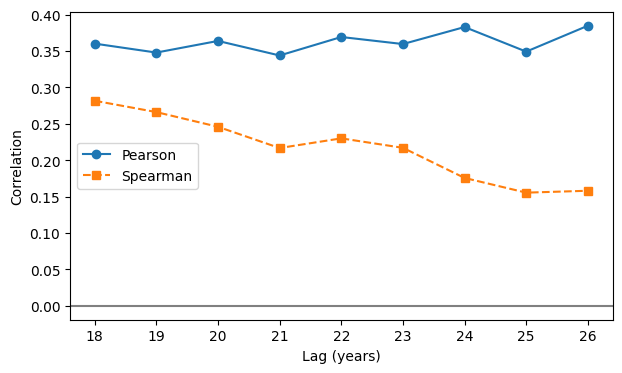

In [84]:
res = lag_corrs(start[start["state"] != "US"])
plt.figure(figsize=(7, 4))
plt.plot(res["lag"], res["pearson_r"], marker="o", label="Pearson")
plt.plot(res["lag"], res["spearman_rho"], marker="s", ls="--", label="Spearman")
plt.axhline(0, color="gray")
plt.xlabel("Lag (years)"); plt.ylabel("Correlation"); plt.legend(); plt.show()

In [85]:
lag_corrs(start[start["state"] != "US"], x="birthrate_100k")

,lag,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,18,204,0.3271,0.0000,0.4217,0.0
1,19,204,0.3250,0.0000,0.4257,0.0
2,20,153,0.3055,0.0001,0.4259,0.0
3,21,153,0.3434,0.0000,0.4377,0.0
4,22,153,0.3406,0.0000,0.4535,0.0
5,23,153,0.3523,0.0000,0.4649,0.0
6,24,102,0.2899,0.0031,0.4057,0.0
7,25,102,0.3343,0.0006,0.4372,0.0
8,26,102,0.3256,0.0008,0.4586,0.0


In [87]:
a = abortions[["state", "year", "abortionstotal", "birthstotal", "population1544"]].copy()
pop = a["population1544"]
a["abortionrate_100k"] = np.where(pop > 0, a["abortionstotal"] / pop * 100_000, np.nan)
a["birthrate_100k"]    = np.where(pop > 0, a["birthstotal"]    / pop * 100_000, np.nan)
a = a[["state", "year", "abortionrate_100k", "birthrate_100k"]]

c = crimes[["state", "year", "total_crime_rate", VIOL, PROP]].rename(
    columns={VIOL: "violent_crime_rate", PROP: "property_crime_rate"})

nolag = c.merge(a, on=["state", "year"], how="inner")
nolag = nolag.dropna(subset=["abortionrate_100k", "birthrate_100k"]).sort_values(["state", "year"])

states_df = nolag[nolag["state"] != "US"]     # all states pooled
us_df     = nolag[nolag["state"] == "US"]     # national series

print("State-year rows:", len(states_df), "| US years:", len(us_df))

State-year rows: 969 | US years: 47


In [88]:
x_vars = ["abortionrate_100k", "birthrate_100k"]
y_vars = ["total_crime_rate", "violent_crime_rate", "property_crime_rate"]

def corr_summary(df):
    rows = []
    for x in x_vars:
        for y in y_vars:
            d = df[[x, y]].dropna()
            if len(d) >= 5:
                r, p = stats.pearsonr(d[x], d[y])
                rho, ps = stats.spearmanr(d[x], d[y])
                rows.append({"x": x, "y": y, "n": len(d), "pearson_r": r, "pearson_p": p,
                             "spearman_rho": rho, "spearman_p": ps})
    return pd.DataFrame(rows).round(4)

In [92]:
corr_summary(us_df)

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,abortionrate_100k,total_crime_rate,47,0.9328,0.0,0.9048,0.0000
1,abortionrate_100k,violent_crime_rate,47,0.7444,0.0,0.8018,0.0000
2,abortionrate_100k,property_crime_rate,47,0.9363,0.0,0.9158,0.0000
3,birthrate_100k,total_crime_rate,47,0.6705,0.0,0.6177,0.0000
4,birthrate_100k,violent_crime_rate,47,0.5563,0.0,0.5062,0.0003
5,birthrate_100k,property_crime_rate,47,0.6705,0.0,0.6240,0.0000


In [89]:
corr_summary(states_df)

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,abortionrate_100k,total_crime_rate,969,0.4771,0.0000,0.3895,0.0
1,abortionrate_100k,violent_crime_rate,969,0.5327,0.0000,0.4179,0.0
2,abortionrate_100k,property_crime_rate,969,0.4337,0.0000,0.3626,0.0
3,birthrate_100k,total_crime_rate,969,0.2737,0.0000,0.3463,0.0
4,birthrate_100k,violent_crime_rate,969,0.0741,0.0211,0.1636,0.0
5,birthrate_100k,property_crime_rate,969,0.3007,0.0000,0.3545,0.0


In [90]:
cols = ["abortionrate_100k", "birthrate_100k", *y_vars]
states_df[cols].corr().round(3)

,abortionrate_100k,birthrate_100k,total_crime_rate,violent_crime_rate,property_crime_rate
abortionrate_100k,1.000,-0.138,0.477,0.533,0.434
birthrate_100k,-0.138,1.000,0.274,0.074,0.301
total_crime_rate,0.477,0.274,1.000,0.758,0.989
violent_crime_rate,0.533,0.074,0.758,1.000,0.655
property_crime_rate,0.434,0.301,0.989,0.655,1.000


In [93]:
cols = ["abortionrate_100k", "birthrate_100k", *y_vars]
us_df[cols].corr().round(3)

,abortionrate_100k,birthrate_100k,total_crime_rate,violent_crime_rate,property_crime_rate
abortionrate_100k,1.000,0.620,0.933,0.744,0.936
birthrate_100k,0.620,1.000,0.670,0.556,0.670
total_crime_rate,0.933,0.670,1.000,0.847,0.998
violent_crime_rate,0.744,0.556,0.847,1.000,0.812
property_crime_rate,0.936,0.670,0.998,0.812,1.000


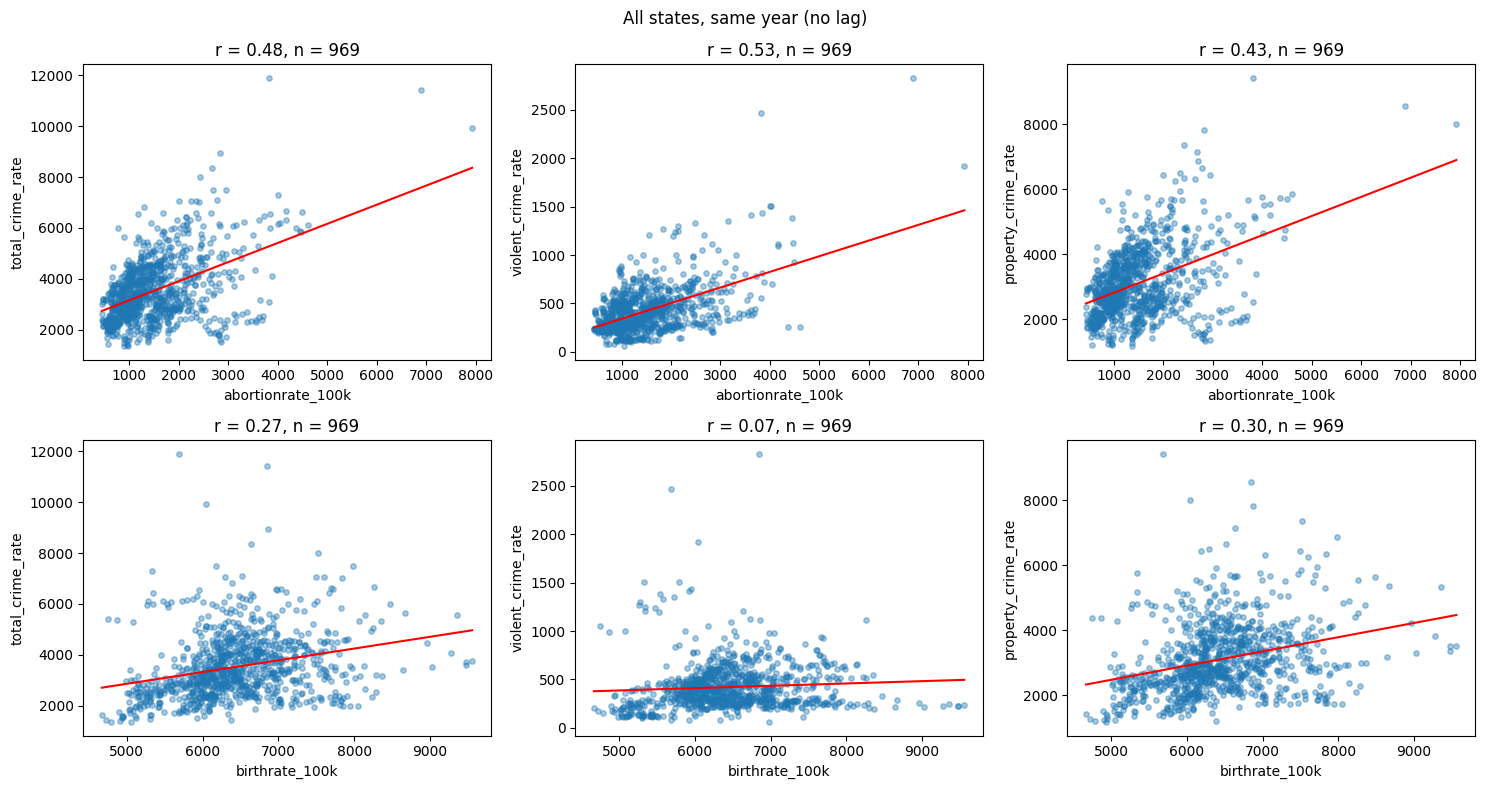

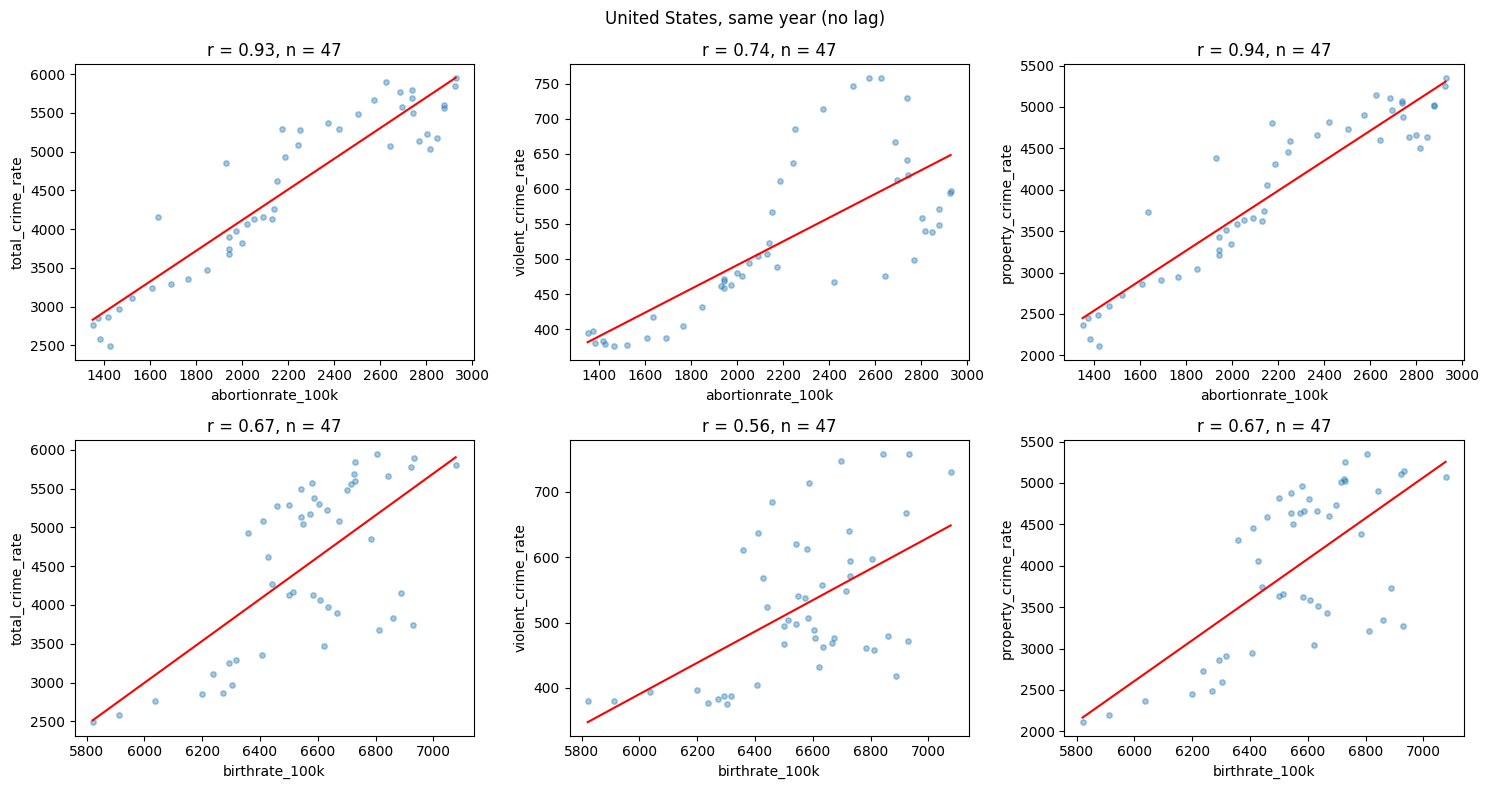

In [91]:
def scatter_grid(df, title):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for i, x in enumerate(x_vars):
        for j, y in enumerate(y_vars):
            ax = axes[i, j]
            d = df[[x, y]].dropna()
            ax.scatter(d[x], d[y], alpha=0.4, s=15)
            if len(d) > 2:
                m, b = np.polyfit(d[x], d[y], 1)
                xs = np.linspace(d[x].min(), d[x].max(), 100)
                ax.plot(xs, m * xs + b, color="red")
                r = d[x].corr(d[y])
                ax.set_title(f"r = {r:.2f}, n = {len(d)}")
            ax.set_xlabel(x)
            ax.set_ylabel(y)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

scatter_grid(states_df, "All states, same year (no lag)")
scatter_grid(us_df, "United States, same year (no lag)")


In [164]:
PROP = "Data.Rates.Property.All"
VIOL = "Data.Rates.Violent.All"
lags = range(18, 27)
crime_vars = {"total": "total_crime_rate", "violent": VIOL, "property": PROP}


st = abortions[abortions["year"].between(1973, 2019)][
    ["state", "year", "abortionstotal", "birthstotal", "population1544"]].copy()
st = st.rename(columns={"year": "start_year"})
pop = st["population1544"]
st["abortionrate_100k"] = np.where(pop > 0, st["abortionstotal"] / pop * 100_000, np.nan)
st["birthrate_100k"]    = np.where(pop > 0, st["birthstotal"]    / pop * 100_000, np.nan)
st = st[st["state"] != "US"].drop(columns=["abortionstotal", "birthstotal", "population1544"])

In [100]:
for lag in lags:
    c = crimes[["state", "year", *crime_vars.values()]].copy()
    c["start_year"] = c["year"] - lag
    c = c.drop(columns="year").rename(columns={v: f"{k}_plus{lag}" for k, v in crime_vars.items()})
    st = st.merge(c, on=["state", "start_year"], how="left")

In [168]:
print(st.shape)
print([col for col in st.columns if col.endswith("plus18")])

(969, 4)
[]


In [104]:



rows = []
for x in ["abortionrate_100k", "birthrate_100k"]:
    for k in crime_vars:
        for lag in lags:
            d = st[[x, f"{k}_plus{lag}"]].dropna()
            if len(d) >= 5:
                r, p = stats.pearsonr(d[x], d[f"{k}_plus{lag}"])
                rho, ps = stats.spearmanr(d[x], d[f"{k}_plus{lag}"])
                rows.append({"exposure": x, "crime": k, "lag": lag, "n": len(d),
                             "pearson_r": r, "pearson_p": p, "spearman_rho": rho, "spearman_p": ps})
pooled = pd.DataFrame(rows).round(4)
pooled

,exposure,crime,lag,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,abortionrate_100k,total,18,204,0.3602,0.0000,0.2817,0.0000
1,abortionrate_100k,total,19,204,0.3479,0.0000,0.2661,0.0001
2,abortionrate_100k,total,20,153,0.3639,0.0000,0.2459,0.0022
3,abortionrate_100k,total,21,153,0.3439,0.0000,0.2167,0.0071
4,abortionrate_100k,total,22,153,0.3693,0.0000,0.2300,0.0042
5,abortionrate_100k,total,23,153,0.3596,0.0000,0.2170,0.0071
6,abortionrate_100k,total,24,102,0.3830,0.0001,0.1756,0.0776
7,abortionrate_100k,total,25,102,0.3492,0.0003,0.1554,0.1189
8,abortionrate_100k,total,26,102,0.3848,0.0001,0.1580,0.1128
9,abortionrate_100k,violent,18,204,0.5138,0.0000,0.3519,0.0000


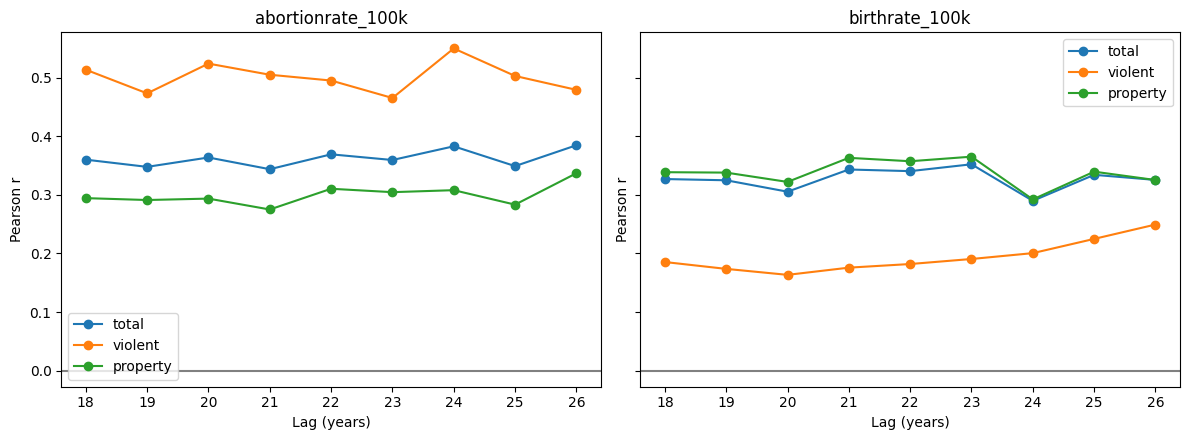

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, x in zip(axes, ["abortionrate_100k", "birthrate_100k"]):
    for k in crime_vars:
        s = pooled[(pooled["exposure"] == x) & (pooled["crime"] == k)]
        ax.plot(s["lag"], s["pearson_r"], marker="o", label=k)
    ax.axhline(0, color="gray")
    ax.set_title(x); ax.set_xlabel("Lag (years)"); ax.set_ylabel("Pearson r"); ax.legend()
plt.tight_layout(); plt.show()

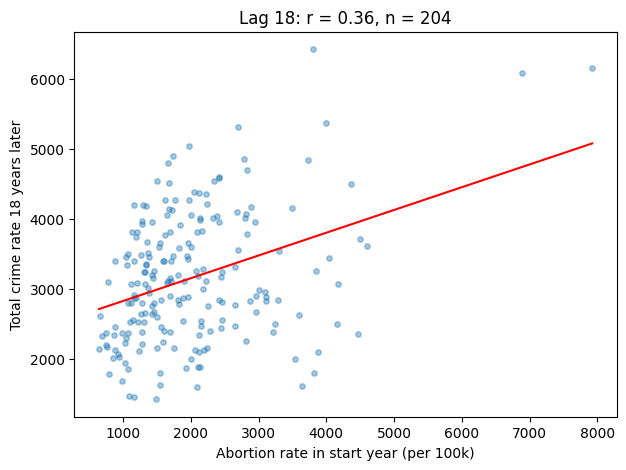

In [107]:
lag = 18
d = st[["state", "abortionrate_100k", f"total_plus{lag}"]].dropna()
plt.figure(figsize=(7, 5))
plt.scatter(d["abortionrate_100k"], d[f"total_plus{lag}"], alpha=0.4, s=15)
m, b = np.polyfit(d["abortionrate_100k"], d[f"total_plus{lag}"], 1)
xs = np.linspace(d["abortionrate_100k"].min(), d["abortionrate_100k"].max(), 100)
plt.plot(xs, m * xs + b, color="red")
plt.xlabel("Abortion rate in start year (per 100k)")
plt.ylabel(f"Total crime rate {lag} years later")
plt.title(f"Lag {lag}: r = {d.iloc[:,1].corr(d.iloc[:,2]):.2f}, n = {len(d)}")
plt.show()

In [111]:
# crime rate stats

print("Crime:", crimes.shape, "1960-2019, 51 states and US")
print("Abortions:", abortions.shape, "1973 - 2020")
print(crimes[["total_crime_rate", VIOL, PROP]].describe().round(1))



Crime: (3115, 23) 1960-2019, 51 states and US
Abortions: (1068, 104) 1973 - 2020
       total_crime_rate  Data.Rates.Violent.All  Data.Rates.Property.All
count            3115.0                  3115.0                   3115.0
mean             3940.1                   397.9                   3542.2
std              1625.3                   287.5                   1418.2
min               650.8                     9.5                    573.1
25%              2721.9                   217.2                   2472.6
50%              3813.4                   342.2                   3438.4
75%              4929.3                   518.2                   4439.1
max             12173.5                  2921.8                   9512.1


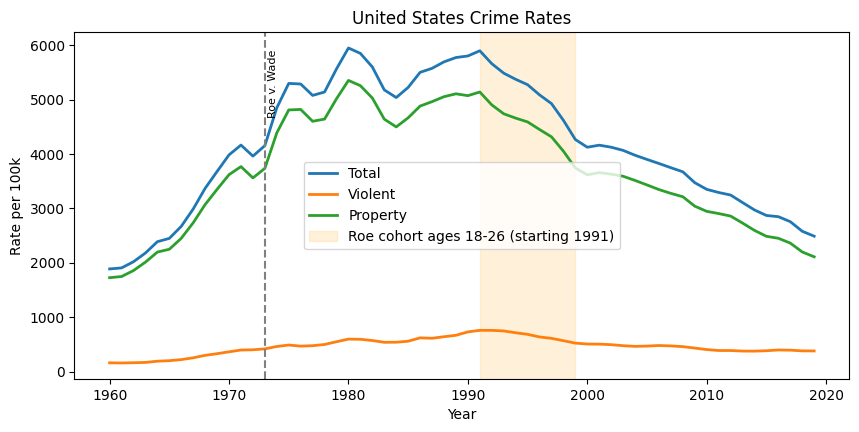

In [143]:
# Crime rates with legalization year and cohort year 18-26 in US

us_c = crimes[crimes["state"] == "US"].sort_values("year")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(us_c["year"], us_c["total_crime_rate"], label="Total", lw=2)
ax.plot(us_c["year"], us_c[VIOL], label="Violent", lw=2)
ax.plot(us_c["year"], us_c[PROP], label="Property", lw=2)
for yr, lab in [(1973, "Roe v. Wade")]:
    ax.axvline(yr, color="gray", ls="--"); ax.text(yr + 0.3, ax.get_ylim()[1] * 0.95, lab, rotation=90, va="top", fontsize=8)
ax.axvspan(1991, 1999, color="orange", alpha=0.15, label="Roe cohort ages 18-26 (starting 1991)")
ax.set_xlabel("Year"); ax.set_ylabel("Rate per 100k");
ax.set_title("United States Crime Rates")
ax.legend();
plt.show()

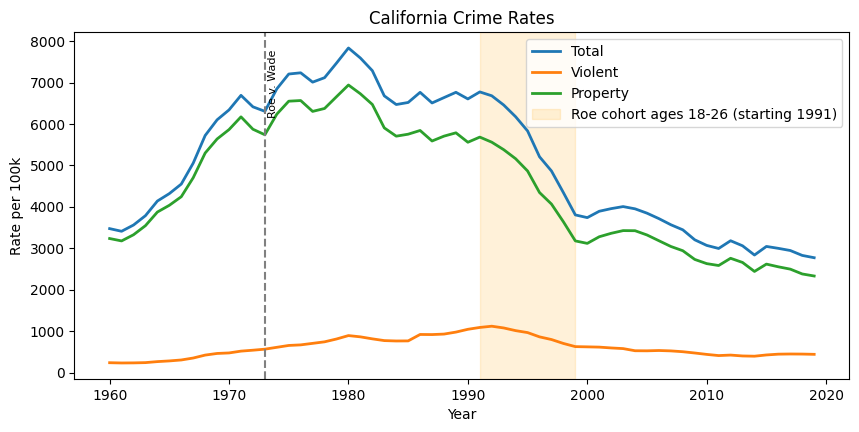

In [142]:
us_ca = crimes[crimes["state"] == "CA"].sort_values("year")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(us_c["year"], us_c["total_crime_rate"], label="Total", lw=2)
ax.plot(us_c["year"], us_c[VIOL], label="Violent", lw=2)
ax.plot(us_c["year"], us_c[PROP], label="Property", lw=2)
for yr, lab in [(1973, "Roe v. Wade")]:
    ax.axvline(yr, color="gray", ls="--"); ax.text(yr + 0.3, ax.get_ylim()[1] * 0.95, lab, rotation=90, va="top", fontsize=8)
ax.axvspan(1991, 1999, color="orange", alpha=0.15, label="Roe cohort ages 18-26 (starting 1991)")
ax.set_xlabel("Year"); ax.set_ylabel("Rate per 100k");
ax.set_title("California Crime Rates")
ax.legend();
plt.show()

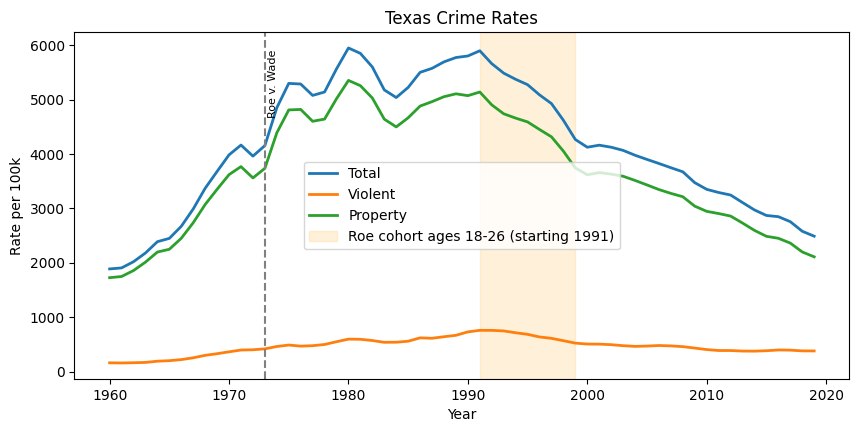

In [144]:
us_tx = crimes[crimes["state"] == "TX"].sort_values("year")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(us_c["year"], us_c["total_crime_rate"], label="Total", lw=2)
ax.plot(us_c["year"], us_c[VIOL], label="Violent", lw=2)
ax.plot(us_c["year"], us_c[PROP], label="Property", lw=2)
for yr, lab in [(1973, "Roe v. Wade")]:
    ax.axvline(yr, color="gray", ls="--"); ax.text(yr + 0.3, ax.get_ylim()[1] * 0.95, lab, rotation=90, va="top", fontsize=8)
ax.axvspan(1991, 1999, color="orange", alpha=0.15, label="Roe cohort ages 18-26 (starting 1991)")
ax.set_xlabel("Year"); ax.set_ylabel("Rate per 100k");
ax.set_title("Texas Crime Rates")
ax.legend();
plt.show();

       abortionrate_100k  birthrate_100k
count             1020.0          1020.0
mean              1475.7          6399.2
std                790.6           755.5
min                414.0          4456.2
25%                942.8          5955.7
50%               1280.7          6333.9
75%               1807.6          6813.9
max               7925.5          9557.0
Missing: {'abortionrate_100k': 0, 'birthrate_100k': 0}
Skewness: {'abortionrate_100k': 1.91, 'birthrate_100k': 0.54}


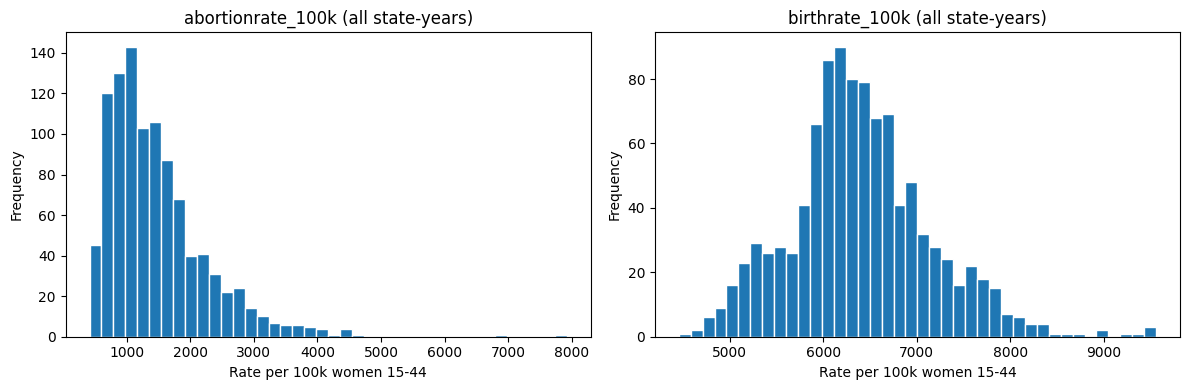

In [131]:
a = abortions.copy()
pop = a["population1544"]
a["abortionrate_100k"] = np.where(pop > 0, a["abortionstotal"] / pop * 100_000, np.nan)
a["birthrate_100k"]    = np.where(pop > 0, a["birthstotal"]    / pop * 100_000, np.nan)

sa = a[a["state"] != "US"].copy()
rate_vars = ["abortionrate_100k", "birthrate_100k"]

print(sa[rate_vars].describe().round(1))
print("Missing:", sa[rate_vars].isna().sum().to_dict())
print("Skewness:", sa[rate_vars].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, rate_vars):
    ax.hist(sa[v].dropna(), bins=40, edgecolor="white")
    ax.set_title(f"{v} (all state-years)")
    ax.set_xlabel("Rate per 100k women 15-44")
    ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()

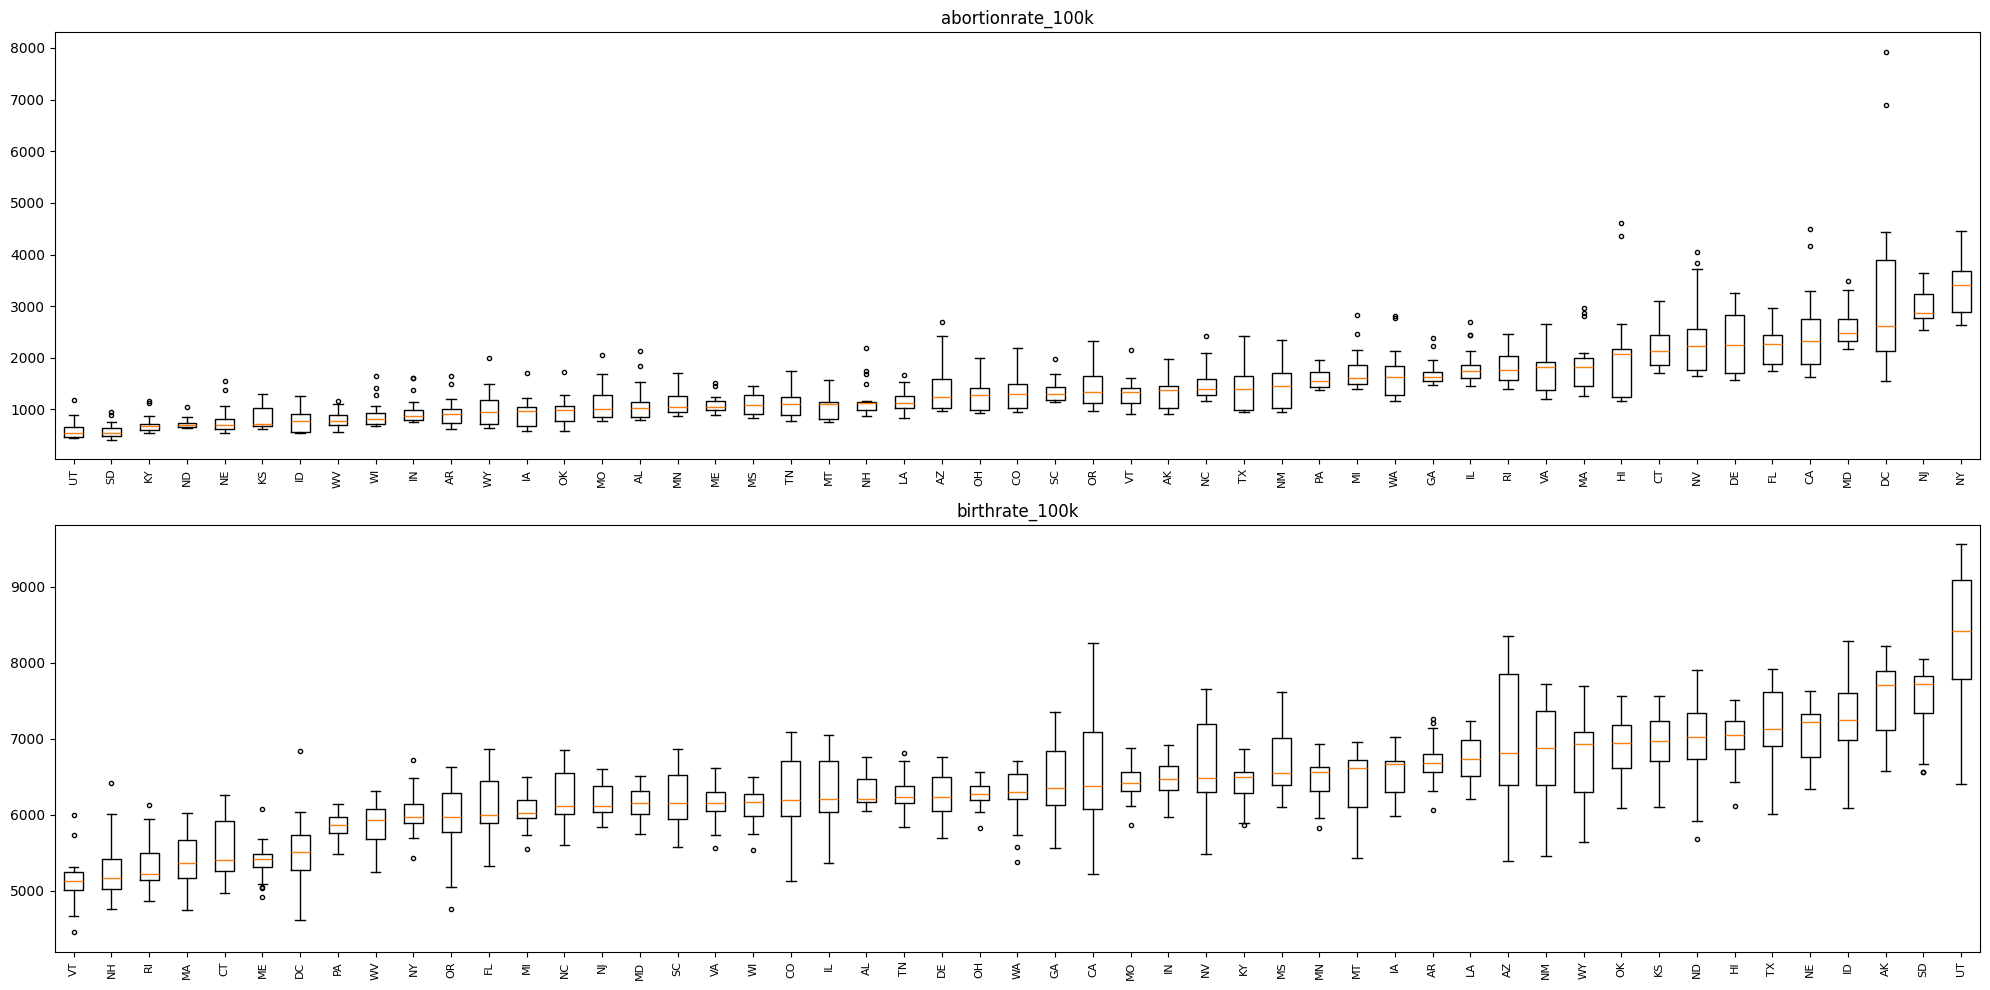

In [135]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
for ax, v in zip(axes, rate_vars):
    order = sa.groupby("state")[v].median().dropna().sort_values().index.tolist()
    ax.boxplot([sa.loc[sa["state"] == st, v].dropna() for st in order],
               tick_labels=order, flierprops={"markersize": 3})
    ax.set_title(v); ax.tick_params(axis="x", rotation=90, labelsize=8)
plt.tight_layout(); plt.show()


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
for ax, v in zip(axes, rate_vars):
    order = sa.groupby("state")[v].median().dropna().sort_values().index.tolist()
    ax.boxplot([sa.loc[sa["state"] == st, v].dropna() for st in order],
               tick_labels=order, flierprops={"markersize": 3})
    ax.set_title(v); ax.tick_params(axis="x", rotation=90, labelsize=8)
plt.tight_layout(); plt.show()

In [136]:
# outliers - DC

for v in rate_vars:
    print(f"\nHighest {v}:")
    display(sa.nlargest(10, v)[["state", "year", v]])


Highest abortionrate_100k:


,state,year,abortionrate_100k
160,DC,1988,7925.546851
161,DC,1992,6894.312192
221,HI,1992,4601.035800
80,CA,1988,4494.540931
641,NY,1992,4462.480140
164,DC,2005,4439.565631
220,HI,1988,4361.485572
81,CA,1992,4170.172118
640,NY,1988,4154.345857
561,NV,1992,4039.969635



Highest birthrate_100k:


,state,year,birthrate_100k
934,UT,2007,9556.995084
933,UT,2006,9476.191741
935,UT,2008,9470.095198
928,UT,1988,9350.314573
932,UT,2005,9280.724082
936,UT,2009,9030.387630
931,UT,2000,8955.328319
929,UT,1992,8668.580590
937,UT,2010,8639.378206
930,UT,1996,8477.334757


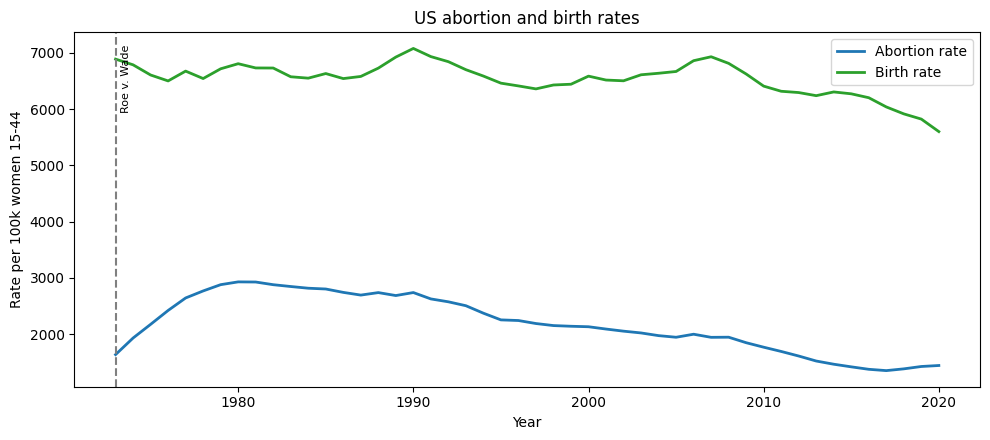

In [153]:
abortion_US = a[a["state"] == "US"].sort_values("year")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(d["year"], d["abortionrate_100k"], color="tab:blue", lw=2, label="Abortion rate")
ax.plot(d["year"], d["birthrate_100k"], color="tab:green", lw=2, label="Birth rate")

ax.axvline(1973, color="gray", ls="--")
ax.text(1973.3, ax.get_ylim()[1] * 0.97, "Roe v. Wade", rotation=90, va="top", fontsize=8)

ax.set_xlabel("Year")
ax.set_ylabel("Rate per 100k women 15-44")
ax.set_title(f"US abortion and birth rates")
ax.legend()
plt.tight_layout()
plt.show()

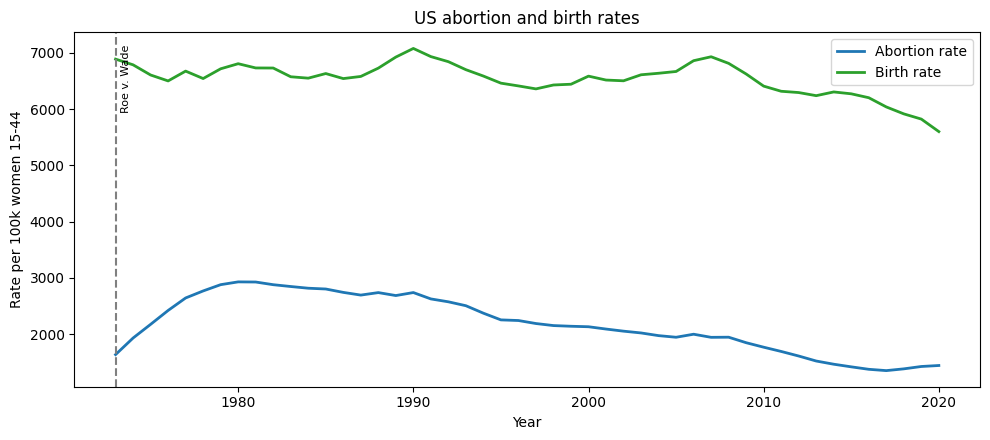

In [154]:
abortion_CA = a[a["state"] == "CA"].sort_values("year")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(d["year"], d["abortionrate_100k"], color="tab:blue", lw=2, label="Abortion rate")
ax.plot(d["year"], d["birthrate_100k"], color="tab:green", lw=2, label="Birth rate")

ax.axvline(1973, color="gray", ls="--")
ax.text(1973.3, ax.get_ylim()[1] * 0.97, "Roe v. Wade", rotation=90, va="top", fontsize=8)

ax.set_xlabel("Year")
ax.set_ylabel("Rate per 100k women 15-44")
ax.set_title(f"US abortion and birth rates")
ax.legend()
plt.tight_layout()
plt.show()

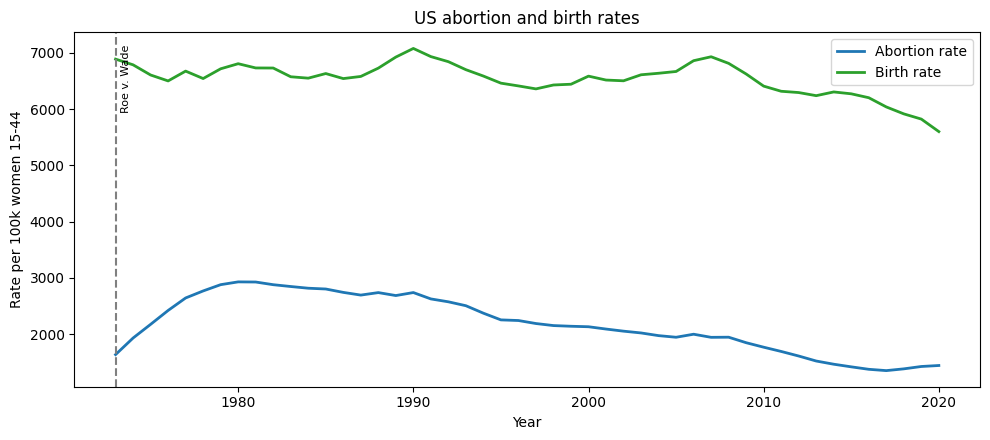

In [155]:
abortion_TX = a[a["state"] == "TX"].sort_values("year")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(d["year"], d["abortionrate_100k"], color="tab:blue", lw=2, label="Abortion rate")
ax.plot(d["year"], d["birthrate_100k"], color="tab:green", lw=2, label="Birth rate")

ax.axvline(1973, color="gray", ls="--")
ax.text(1973.3, ax.get_ylim()[1] * 0.97, "Roe v. Wade", rotation=90, va="top", fontsize=8)

ax.set_xlabel("Year")
ax.set_ylabel("Rate per 100k women 15-44")
ax.set_title(f"US abortion and birth rates")
ax.legend()
plt.tight_layout()
plt.show()

In [172]:
PROP = "Data.Rates.Property.All"
VIOL = "Data.Rates.Violent.All"
lags = range(18, 27)
crime_vars = {"total": "total_crime_rate", "violent": VIOL, "property": PROP}

# build the base table
st = abortions[abortions["year"].between(1973, 2019)][
    ["state", "year", "abortionstotal", "birthstotal", "population1544"]].copy()
st = st.rename(columns={"year": "start_year"})
pop = st["population1544"]
st["abortionrate_100k"] = np.where(pop > 0, st["abortionstotal"] / pop * 100_000, np.nan)
st["birthrate_100k"]    = np.where(pop > 0, st["birthstotal"]    / pop * 100_000, np.nan)
st = st[st["state"] != "US"].drop(columns=["abortionstotal", "birthstotal", "population1544"])

# add crime at each lag
for lag in lags:
    c = crimes[["state", "year", *crime_vars.values()]].copy()
    c["start_year"] = c["year"] - lag
    c = c.drop(columns="year").rename(columns={v: f"{k}_plus{lag}" for k, v in crime_vars.items()})
    st = st.merge(c, on=["state", "start_year"], how="left")

print(st.shape)

(969, 31)
['total_plus18', 'violent_plus18', 'property_plus18']


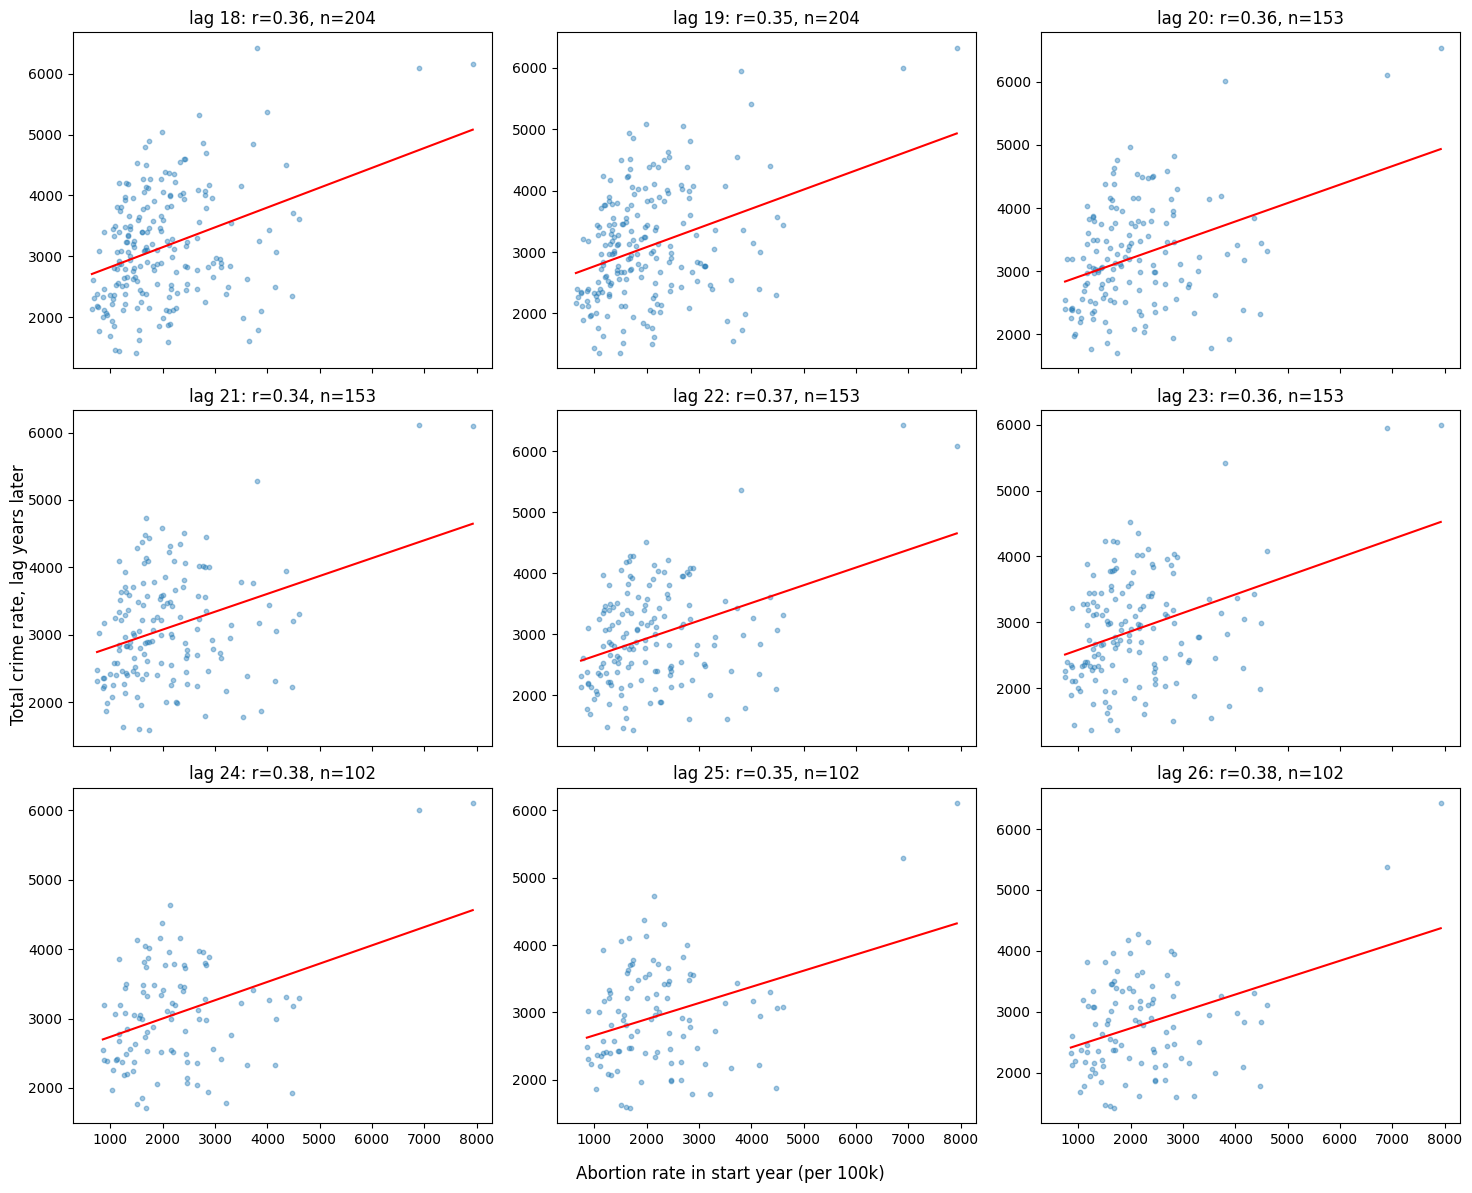

In [175]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
for ax, l in zip(axes.ravel(), lags):
    d = st[["abortionrate_100k", f"total_plus{l}"]].dropna()
    ax.scatter(d["abortionrate_100k"], d[f"total_plus{l}"], s=10, alpha=0.4)
    if len(d) > 2:
        m, b = np.polyfit(d["abortionrate_100k"], d[f"total_plus{l}"], 1)
        xs = np.linspace(d["abortionrate_100k"].min(), d["abortionrate_100k"].max(), 50)
        ax.plot(xs, m * xs + b, color="red")
        ax.set_title(f"lag {l}: r={d.iloc[:,0].corr(d.iloc[:,1]):.2f}, n={len(d)}")
fig.supxlabel("Abortion rate in start year (per 100k)")
fig.supylabel("Total crime rate, lag years later")
plt.tight_layout(); plt.show()

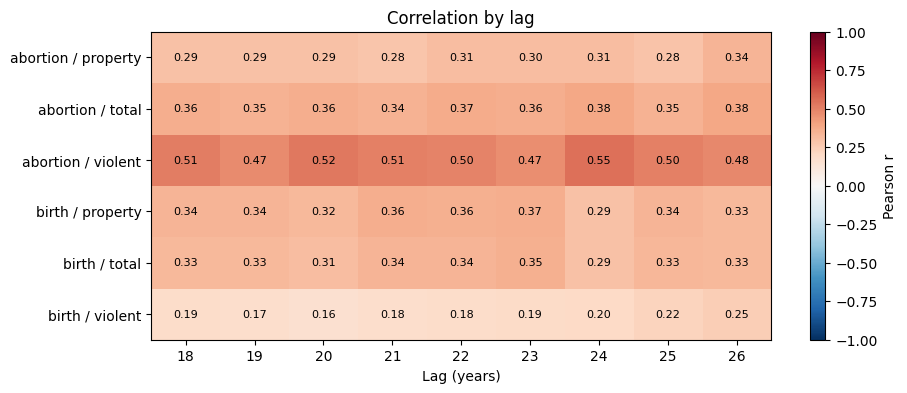

In [176]:
rows = []
for x in ["abortionrate_100k", "birthrate_100k"]:
    for k in ["total", "violent", "property"]:
        for l in lags:
            d = st[[x, f"{k}_plus{l}"]].dropna()
            rows.append({"row": f"{x[:-9]} / {k}", "lag": l, "r": d[x].corr(d[f"{k}_plus{l}"]) if len(d) > 4 else np.nan})
hm = pd.DataFrame(rows).pivot(index="row", columns="lag", values="r")

plt.figure(figsize=(10, 4))
plt.imshow(hm, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Pearson r")
plt.xticks(range(len(hm.columns)), hm.columns); plt.yticks(range(len(hm.index)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        if pd.notna(hm.iloc[i, j]):
            plt.text(j, i, f"{hm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.xlabel("Lag (years)"); plt.title("Correlation by lag"); plt.show()

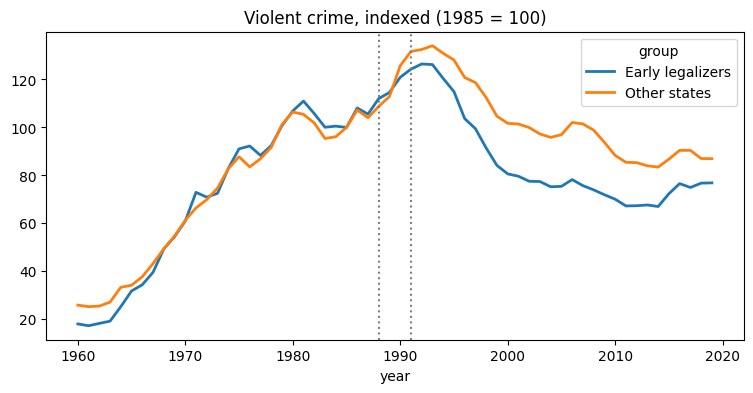

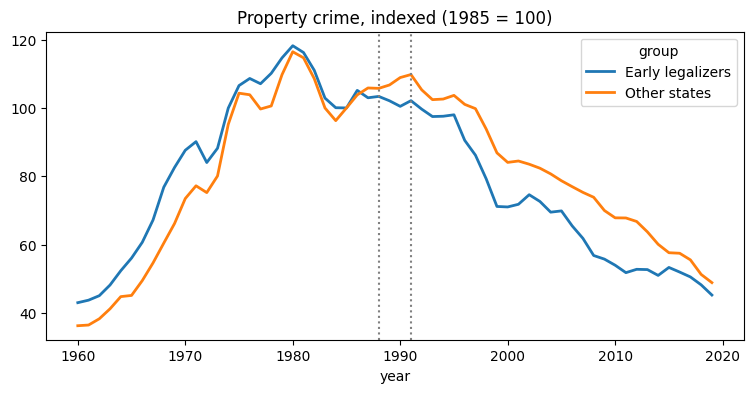

In [177]:
# these states had early legalization of abortion, comparing violent and property crime vs other states

EARLY = ["NY", "CA", "WA", "AK", "HI"]
s = crimes[(crimes["state"] != "US") & (crimes["state"] != "DC")].copy()
s["group"] = np.where(s["state"].isin(EARLY), "Early legalizers", "Other states")

for v, name in [("Data.Rates.Violent.All", "Violent"), ("Data.Rates.Property.All", "Property")]:
    g = s.groupby(["group", "year"])[v].mean().unstack(0)
    g = g / g.loc[1985] * 100          # index to 1985 = 100
    g.plot(figsize=(9, 4), lw=2, title=f"{name} crime, indexed (1985 = 100)")
    plt.axvline(1988, color="gray", ls=":"); plt.axvline(1991, color="gray", ls=":")
    plt.show()





